# A/B-тест алгоритма рекомендаций развлекательного приложения

Вы работаете продуктовым аналитиком в компании, которая разрабатывает развлекательное приложение с функцией «бесконечной» ленты, как, например, в приложениях с короткими видео. В вашем приложении существует две модели монетизации: первая — ежемесячная платная подписка, которая позволяет пользователям смотреть ленту без рекламы, вторая — демонстрация рекламы для пользователей, которые ещё не оформили подписку.

Команда разработчиков рекомендательных систем создала новый алгоритм рекомендаций, который, по их мнению, будет показывать более интересный контент для каждого пользователя. Вас, как аналитика, просят помочь рассчитать параметры A/B-теста, который позволит проверить эту гипотезу, и проанализировать его результаты.

## Описание данных

Вы будете работать с тремя таблицами:

- `sessions_project_history.csv` — таблица с историческими данными по сессиям пользователей на период с 2025-08-15 по 2025-09-23. Путь к файлу: `/datasets/sessions_project_history.csv`.

- `sessions_project_test_part.csv` — таблица с данными за первый день проведения A/B-теста, то есть за 2025-10-14. Путь к файлу: `/datasets/sessions_project_test_part.csv`.

- `sessions_project_test.csv` — таблица с данными за весь период проведения A/B-теста, то есть с 2025-10-14 по 2025-11-02. Путь к файлу: `/datasets/sessions_project_test.csv`.

У этих таблиц почти совпадает структура и содержание колонок, различаются лишь периоды наблюдения.

Поля таблиц `sessions_project_history.csv`, `sessions_project_test.csv`, `sessions_project_test_part.csv`:

- `user_id` — идентификатор пользователя;

- `session_id` — идентификатор сессии в приложении;

- `session_date` — дата сессии;

- `session_start_ts` — дата и время начала сессии;

- `install_date` — дата установки приложения;

- `session_number` — порядковый номер сессии для конкретного пользователя;

- `registration_flag` — является ли пользователь зарегистрированным;

- `page_counter` — количество просмотренных страниц во время сессии;

- `region` — регион пользователя;

- `device` — тип устройства пользователя;

- `test_group` — тестовая группа (в таблице с историческими данными этого столбца нет).


## Что нужно сделать
Ваши задачи: рассчитать параметры теста, оценить корректность его проведения и проанализировать результаты эксперимента.

### 1. Работа с историческими данными (EDA)

#### 1.1. Загрузка исторических данных
На первом этапе поработайте с историческими данными приложения:

- Импортируйте библиотеку pandas.

- Считайте и сохраните в датафрейм `sessions_history` CSV-файл с историческими данными о сессиях пользователей `sessions_project_history.csv`.

Выведите на экран первые пять строк полученного датафрейма.

In [1]:
import pandas as pd

# Считываем файл в датафрейм
sessions_history = pd.read_csv('/datasets/sessions_project_history.csv')

# Смотрим на первые 5 строк, чтобы убедиться, что всё загрузилось
sessions_history.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android


In [2]:
# Дополнительно выводим информацию о датафрейме
sessions_history.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 435924 entries, 0 to 435923
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   user_id            435924 non-null  object
 1   session_id         435924 non-null  object
 2   session_date       435924 non-null  object
 3   session_start_ts   435924 non-null  object
 4   install_date       435924 non-null  object
 5   session_number     435924 non-null  int64 
 6   registration_flag  435924 non-null  int64 
 7   page_counter       435924 non-null  int64 
 8   region             435924 non-null  object
 9   device             435924 non-null  object
dtypes: int64(3), object(7)
memory usage: 33.3+ MB


#### 1.2. Знакомство с данными
- Для каждого уникального пользователя `user_id` рассчитайте количество уникальных сессий `session_id`.

- Выведите на экран все данные из таблицы `sessions_history` для одного пользователя с наибольшим количеством сессий. Если таких пользователей несколько, выберите любого из них.

- Изучите таблицу для одного пользователя, чтобы лучше понять логику формирования каждого столбца данных.

In [3]:
# Группируем данные по user_id и считаем число сессий
# результат сортируем по возрастанию
sessions_history.groupby('user_id')['session_id'].count().sort_values(ascending=False)

user_id
10E0DEFC1ABDBBE0    10
6A73CB5566BB494D    10
8A60431A825D035B     9
D11541BAC141FB94     9
5BCFE7C4DCC148E9     9
                    ..
1DF13BB1953B3497     1
628502A3CE7E0A3C     1
1DEEF40DEFBD0C65     1
AC08479B7472C628     1
8A0882B6715D9EE5     1
Name: session_id, Length: 134039, dtype: int64

In [4]:
# Выводим всю информацию об одном из двух самых активных пользователей
sessions_history[sessions_history['user_id'] == '10E0DEFC1ABDBBE0']

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
115558,10E0DEFC1ABDBBE0,B8F0423BBFFCF5DC,2025-08-14,2025-08-14 13:57:39,2025-08-14,1,0,4,CIS,Android
191751,10E0DEFC1ABDBBE0,87CA2FA549473837,2025-08-15,2025-08-15 16:42:10,2025-08-14,2,0,3,CIS,Android
239370,10E0DEFC1ABDBBE0,4ADD8011DCDCE318,2025-08-16,2025-08-16 19:53:21,2025-08-14,3,0,3,CIS,Android
274629,10E0DEFC1ABDBBE0,DF0FD0E09BF1F3D7,2025-08-17,2025-08-17 15:03:43,2025-08-14,4,0,1,CIS,Android
302501,10E0DEFC1ABDBBE0,3C221774B4DE6885,2025-08-18,2025-08-18 17:29:14,2025-08-14,5,0,4,CIS,Android
325557,10E0DEFC1ABDBBE0,031BD7A67048105B,2025-08-19,2025-08-19 13:23:55,2025-08-14,6,0,2,CIS,Android
345336,10E0DEFC1ABDBBE0,FF4315CF4AD4B100,2025-08-20,2025-08-20 19:31:54,2025-08-14,7,0,2,CIS,Android
377532,10E0DEFC1ABDBBE0,4045FEA0747203B4,2025-08-22,2025-08-22 17:54:13,2025-08-14,8,0,2,CIS,Android
403538,10E0DEFC1ABDBBE0,344B086C421C7F37,2025-08-24,2025-08-24 14:46:13,2025-08-14,9,0,2,CIS,Android
414743,10E0DEFC1ABDBBE0,054F20BA371E4C9D,2025-08-25,2025-08-25 18:36:41,2025-08-14,10,0,3,CIS,Android


#### 1.3. Анализ числа регистраций
Одна из важнейших метрик продукта — число зарегистрированных пользователей. Используя исторические данные, визуализируйте, как менялось число регистраций в приложении за время его существования. Пользователь считается зарегистрированным только в день совершения регистрации. Таким образом, вам необходимо проанализировать количество зарегистрированных активных пользователей за каждый день без накопления (аналог DAU, но для регистраций пользователей).

- Агрегируйте исторические данные и рассчитайте число уникальных пользователей и число зарегистрированных пользователей для каждого дня наблюдения. Для простоты считайте, что у пользователя в течение дня бывает одна сессия максимум и статус регистрации в течение одного дня не может измениться.

- Постройте линейные графики общего числа пользователей и общего числа зарегистрированных пользователей по дням. Отобразите их на одном графике.

- Постройте отдельный линейный график доли зарегистрированных пользователей от всех пользователей по дням.

- На обоих графиках должны быть заголовок, подписанные оси X и Y, сетка и легенда.

In [5]:
import matplotlib.pyplot as plt

In [6]:
# Преобразуем колонку с датой сессии в формат datetime
sessions_history['session_date'] = pd.to_datetime(sessions_history['session_date'])
sessions_history['session_date'].head()

0   2025-08-15
1   2025-08-15
2   2025-08-15
3   2025-08-15
4   2025-08-15
Name: session_date, dtype: datetime64[ns]

In [7]:
# Группируем данные по дням 
daily_group = sessions_history.groupby('session_date').agg(
    total_users=('user_id', 'nunique'), # Считаем общее кол-во пользователей
    registered_users=('registration_flag', 'sum') # Считаем кол-во зарегестрированных пользователей
)
# Выводим первые 5 строк для проверки
daily_group.head()

,total_users,registered_users
session_date,,
2025-08-11,3919,169
2025-08-12,6056,336
2025-08-13,8489,464
2025-08-14,10321,625
2025-08-15,14065,840


In [8]:
# Создаем столбец с долей зарегестрированных пользователей
daily_group['share'] = daily_group['registered_users'] / daily_group['total_users']
# Выводим первые 5 строк для проверки
daily_group.head()

,total_users,registered_users,share
session_date,,,
2025-08-11,3919,169,0.043123
2025-08-12,6056,336,0.055482
2025-08-13,8489,464,0.054659
2025-08-14,10321,625,0.060556
2025-08-15,14065,840,0.059723


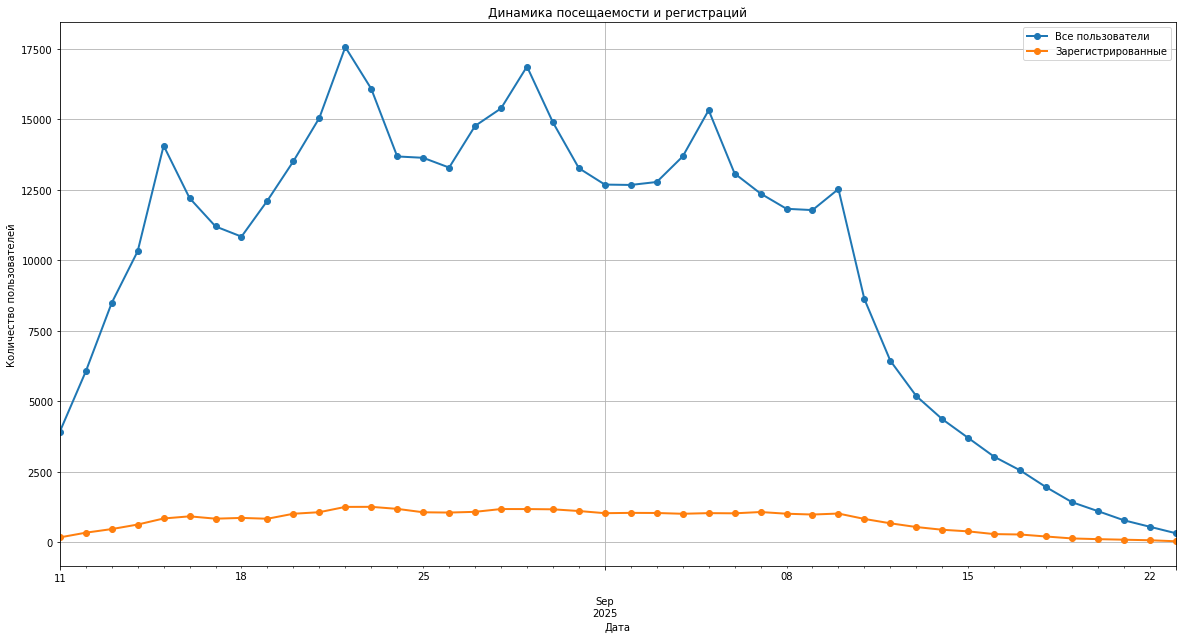

In [9]:
# График 1: Общее число и регистрации
plt.figure(figsize=(20, 10))
daily_group[['total_users', 'registered_users']].plot(
    kind='line', 
    marker='o',
    linewidth=2,
    ax=plt.gca(), 
    grid=True
)
plt.title('Динамика посещаемости и регистраций')
plt.xlabel('Дата')
plt.ylabel('Количество пользователей')
plt.legend(['Все пользователи', 'Зарегистрированные'])
plt.show()

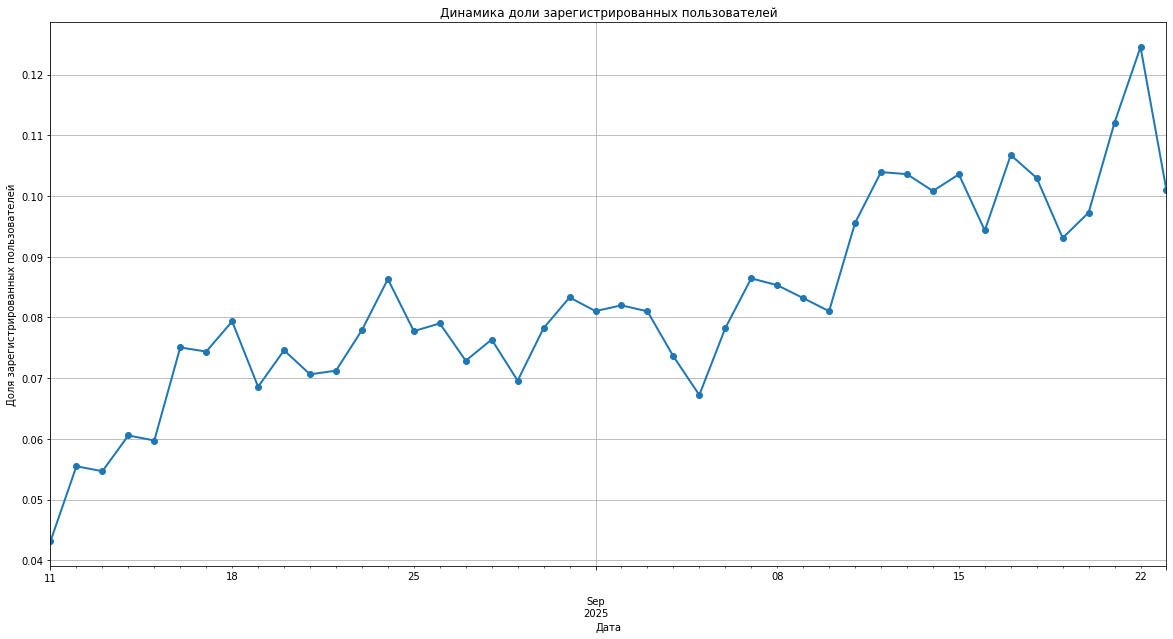

In [10]:
# График 2: Доля зарегестрированных пользователей
plt.figure(figsize=(20, 10))
daily_group['share'].plot(
    kind='line', 
    marker='o',
    linewidth=2, 
    grid=True
)
plt.title('Динамика доли зарегистрированных пользователей')
plt.xlabel('Дата')
plt.ylabel('Доля зарегистрированных пользователей')
plt.show()

#### 1.4. Анализ числа просмотренных страниц
Другая важная метрика продукта — число просмотренных страниц в приложении. Чем больше страниц просмотрено, тем сильнее пользователь увлечён контентом, а значит, выше шансы, что он зарегистрируется и оплатит подписку.

В рамках задания проанализируйте число просмотренных страниц во время первых сессий пользователей. Найдите количество первых сессий для каждого значения количества просмотренных страниц. Например: одну страницу просмотрели в 29 160 сессиях, две страницы — в 105 536 сессиях и так далее.

- Постройте столбчатую диаграмму, где по оси X будет число просмотренных страниц, по оси Y — количество сессий.

- На диаграмме должны быть заголовок, подписанные оси X и Y.

In [11]:
# Группируем данные по кол-ву просмотров и считаем кол-во сессий
f_sessions = sessions_history[sessions_history['session_number'] == 1]
f_session_group = f_sessions.groupby('page_counter')['session_id'].count()


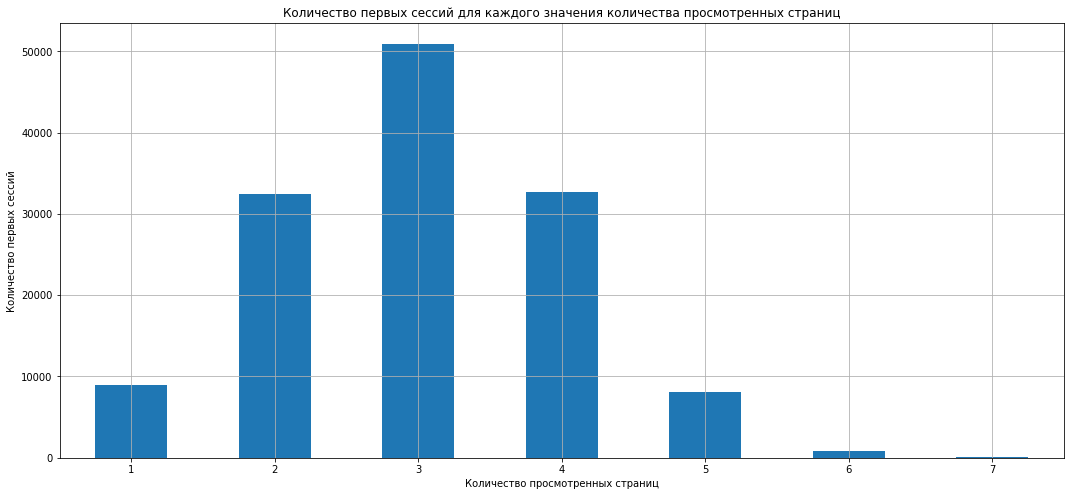

In [12]:
# График кол-ва первых сессий для каждого значения количества просмотренных страниц
plt.figure(figsize=(18, 8))
f_session_group.plot( 
    kind='bar',
    rot=0, 
    legend=False, 
    title=f'Количество первых сессий для каждого значения количества просмотренных страниц'
)
plt.xlabel('Количество просмотренных страниц')
plt.ylabel('Количество первых сессий')
plt.grid()

#### 1.5. Доля пользователей, просмотревших более четырёх страниц
Продуктовая команда продукта считает, что сессии, в рамках которых пользователь просмотрел 4 и более страниц, говорят об удовлетворённости контентом и алгоритмами рекомендаций. Этот показатель является важной прокси-метрикой для продукта.

- В датафрейме `sessions_history` создайте дополнительный столбец `good_session`. В него войдёт значение `1`, если за одну сессию было просмотрено 4 и более страниц, и значение `0`, если было просмотрено меньше.

- Постройте график со средним значением доли успешных сессий от всех первых сессий пользователей. Данные нужно визуализировать по дням за весь период наблюдения.

In [13]:
# Добавляем новый столбец с индикацией того, была ли сессия "хорошей"
sessions_history['good_session'] = (sessions_history['page_counter'] >= 4).astype(int)
# Вывоим первые 5 строк
sessions_history.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,good_session
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone,0
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android,1
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC,1
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android,1
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android,0


In [14]:
# Считаем долю упешных сессий
f_sessions = sessions_history[sessions_history['session_number'] == 1]
daily_good_sessions = f_sessions.groupby('session_date')['good_session'].mean()

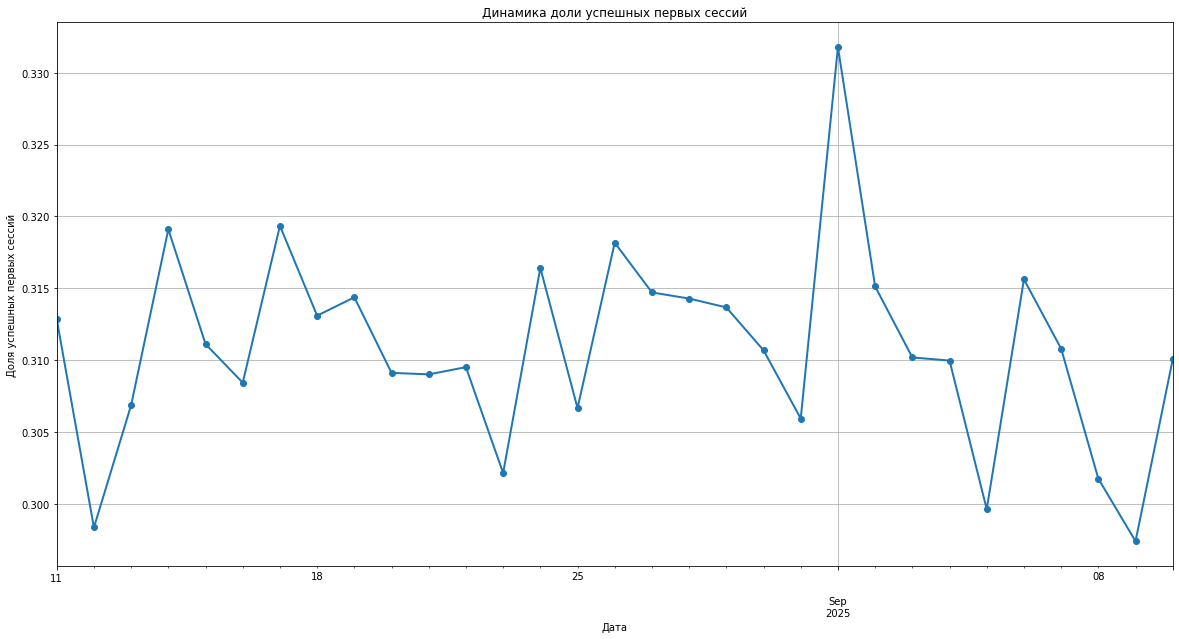

In [15]:
# График доли упешных сессий
plt.figure(figsize=(20, 10))
daily_good_sessions.plot(
    kind='line', 
    marker='o',
    linewidth=2, 
    grid=True
)
plt.title('Динамика доли успешных первых сессий')
plt.xlabel('Дата')
plt.ylabel('Доля успешных первых сессий')
plt.show()

### 2. Подготовка к тесту
При планировании теста необходимо проделать несколько важных шагов:

- Определиться с целевой метрикой.

- Рассчитать необходимый размер выборки.

- Исходя из текущих значений трафика рассчитать необходимую длительность проведения теста.

#### 2.1. Расчёт размера выборки
В рамках курса вы уже рассчитывали размеры выборки и  использовали для этого онлайн-калькулятор. В этом задании предлагаем воспользоваться готовым кодом и рассчитать необходимое для вашего эксперимента количество пользователей.

Для этого установите в коде ниже следующие параметры:

- Уровень значимости — 0.05.

- Вероятность ошибки второго рода — 0.2.

- Мощность теста.

- Минимальный детектируемый эффект, или MDE, — 3%. Обратите внимание, что здесь нужно указать десятичную дробь, а не процент.

При расчёте размера выборки используйте метод `solve_power()` из класса `power.NormalIndPower` модуля `statsmodels.stats`.

Запустите ячейку и изучите полученное значение.

In [16]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

# Задаем параметры:
alpha = 0.05  # Уровень значимости
beta = 0.2  # Ошибка второго рода
power = 1 - beta # Мощность теста
p = 0.3 # Базовый уровень доли
mde = p * 0.03  # Минимальный детектируемый эффект
effect_size = proportion_effectsize(p, p + mde)

# Инициализируем класс NormalIndPower
power_analysis = NormalIndPower()

# Расчёт размера выборки
sample_size = power_analysis.solve_power(
    effect_size = effect_size,
    power = power,
    alpha = alpha,
    ratio = 1 # Равномерное распределение выборок
)

print(f"Необходимый размер выборки для каждой группы: {int(sample_size)}")

Необходимый размер выборки для каждой группы: 41040


#### 2.2. Расчёт длительности A/B-теста

Используйте данные о количестве пользователей в каждой выборке и среднем количестве пользователей приложения. Рассчитайте длительность теста, разделив одно на другое.

- Рассчитайте среднее количество уникальных пользователей приложения в день.

- Определите длительность теста исходя из рассчитанного значения размера выборок и среднего дневного трафика приложения. Количество дней округлите в большую сторону.

In [17]:
import math

# Среднее количество пользователей приложения в день по историческим данным
avg_daily_users = sessions_history.groupby('session_date')['user_id'].nunique().mean()

# Рассчитываем длительность теста в днях как отношение размера выборки к среднему числу пользователей
test_duration = math.ceil((sample_size*2) / avg_daily_users)

print(f"Рассчитанная длительность A/B-теста при текущем уровене трафика в {avg_daily_users} пользователей в день составит {test_duration} дней")

Рассчитанная длительность A/B-теста при текущем уровене трафика в 9907.363636363636 пользователей в день составит 9 дней


### 3. Мониторинг А/В-теста

#### 3.1. Проверка распределения пользователей

A/B-тест успешно запущен, и уже доступны данные за первые три дня. На этом этапе нужно убедиться, что всё идёт хорошо: пользователи разделены правильным образом, а интересующие вас метрики корректно считаются.

- Считайте и сохраните в датафрейм `sessions_test_part` CSV-файл с историческими данными о сессиях пользователей `sessions_project_test_part.csv`.

- Рассчитайте количество уникальных пользователей в каждой из экспериментальных групп для одного дня наблюдения.

- Рассчитайте и выведите на экран процентную разницу в количестве пользователей в группах A и B. Постройте любую удобную визуализацию, на которой будет видно возможное различие двух групп.

Для расчёта процентной разницы воспользуйтесь формулой:
$$P = 100 \cdot  \frac{|A − B|}{A}$$

In [18]:
# Создаем датафрейм с данными за первые 3 дня тестирования
sessions_test_part = pd.read_csv('/datasets/sessions_project_test_part.csv')

In [19]:
# Выводим первые 5 строк датафрейма
sessions_test_part.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group
0,3404844B53442747,B4901323BD537E45,2025-10-14,2025-10-14 19:28:49,2025-10-14,1,0,3,CIS,Android,B
1,3A2BF4D364E62D89,216FC619308F8788,2025-10-14,2025-10-14 21:11:04,2025-10-14,1,0,3,MENA,iPhone,A
2,79CDAE11E32B1597,EDFCE4AC1A504074,2025-10-14,2025-10-14 21:44:03,2025-10-14,1,0,3,CIS,iPhone,A
3,D6AF8D78297A931F,CF0AC0EEDE92C690,2025-10-14,2025-10-14 19:07:55,2025-10-14,1,0,4,CIS,PC,A
4,37E0CE723AE568E0,2E6ED45E8C86C4E9,2025-10-14,2025-10-14 15:39:44,2025-10-14,1,0,3,CIS,Mac,B


In [20]:
# Считаем кол-во пользователей в группах а и б
sesiions_groups_cnt = sessions_test_part.groupby('test_group')['user_id'].nunique()
sesiions_groups_cnt

test_group
A    1477
B    1466
Name: user_id, dtype: int64

In [21]:
a_count = sesiions_groups_cnt['A'] # Сохраняем кол-во пользователей в группе а
b_count = sesiions_groups_cnt['B'] # Сохраняем кол-во пользователей в группе б

# Вычисляем по формуле процентную разницу в кол-ве пользователей в обеих группах
p = 100 * abs(a_count - b_count) / a_count
p

0.7447528774542993

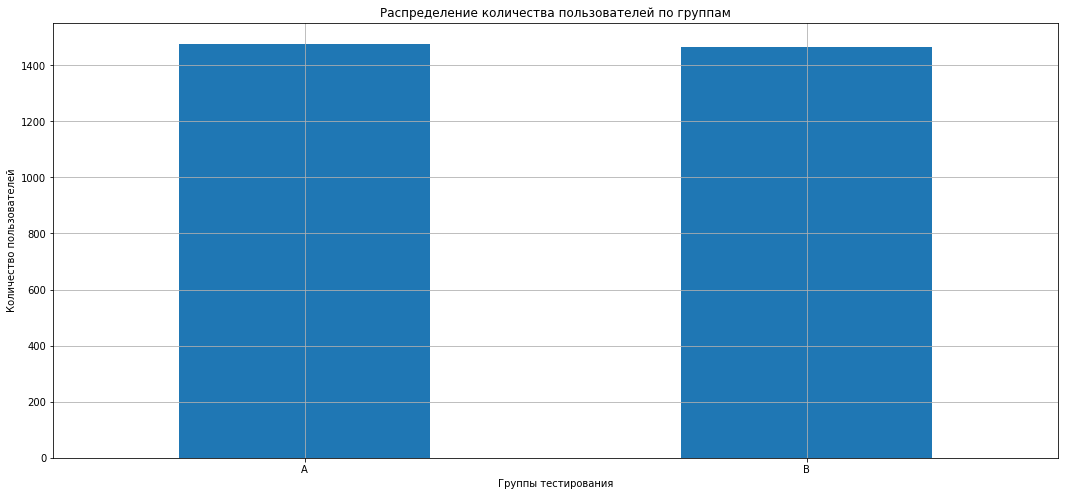

In [22]:
# График распределения пользователей по группам
plt.figure(figsize=(18, 8))
sesiions_groups_cnt.plot( 
    kind='bar', 
    rot=0, 
    legend=False, 
    title=f'Распределение количества пользователей по группам'
)
plt.xlabel('Группы тестирования')
plt.ylabel('Количество пользователей')
plt.grid()

#### 3.2. Проверка пересечений пользователей
Помимо проверки равенства количества пользователей в группах, полезно убедиться в том, что группы независимы. Для этого нужно убедиться, что никто из пользователей случайно не попал в обе группы одновременно.

- Рассчитайте количество пользователей, которые встречаются одновременно в группах A и B, или убедитесь, что таких нет.

In [23]:
# Находим ID пользователей для каждой группы
users_a = set(sessions_test_part[sessions_test_part['test_group'] == 'A']['user_id'])
users_b = set(sessions_test_part[sessions_test_part['test_group'] == 'B']['user_id'])

# Находим пересечение 
common_users = users_a.intersection(users_b)
len(common_users)

0

#### 3.3. Равномерность разделения пользователей по устройствам
Полезно также убедиться в том, что пользователи равномерно распределены по всем доступным категориальным переменным — типам устройств и регионам.

Постройте две диаграммы:

- доля каждого типа устройства для пользователей из группы A,

- доля каждого типа устройства для пользователей из группы B.

Постарайтесь добавить на диаграммы все необходимые подписи, пояснения и заголовки, которые позволят сделать вывод о том, совпадает ли распределение устройств в группах A и B.


In [24]:
# Сохраняем данные по пользователям группы А и Б по отедльности
group_a = sessions_test_part[sessions_test_part['test_group'] == 'A']
group_b = sessions_test_part[sessions_test_part['test_group'] == 'B']

In [25]:
# Считаем долю использования различных платформ в группах А и Б по отедльности
a_device = group_a.groupby('device')['user_id'].nunique()
b_device = group_b.groupby('device')['user_id'].nunique()
a_device_share = a_device / group_a['user_id'].nunique()
b_device_share = b_device / group_b['user_id'].nunique()

print(f' Группа А \n {a_device_share}, \n Группа Б \n {b_device_share}')

 Группа А 
 device
Android    0.444144
Mac        0.105619
PC         0.249831
iPhone     0.200406
Name: user_id, dtype: float64, 
 Группа Б 
 device
Android    0.455662
Mac        0.100955
PC         0.259891
iPhone     0.183492
Name: user_id, dtype: float64


In [26]:
group_a['user_id'].nunique()

1477

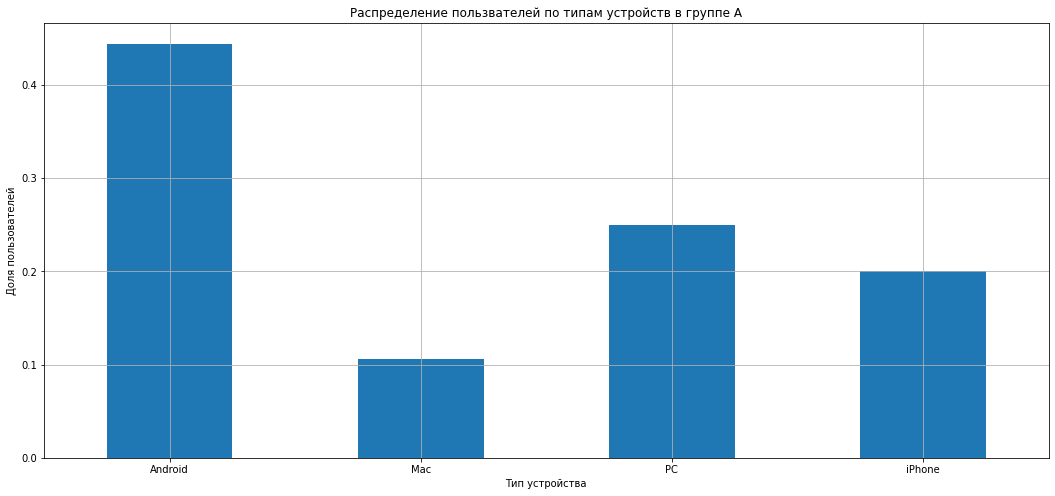

In [27]:
# График 1: Распределение пользвателей по типам устройств в группе А
plt.figure(figsize=(18, 8))
a_device_share.plot( 
    kind='bar', 
    rot=0, 
    legend=False, 
    title=f'Распределение пользвателей по типам устройств в группе А'
)
plt.xlabel('Тип устройства')
plt.ylabel('Доля пользователей')
plt.grid()

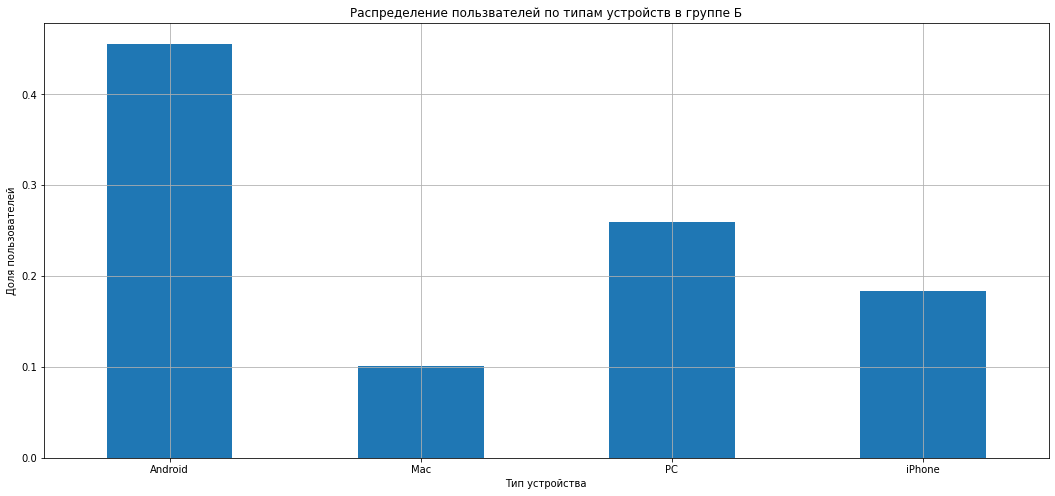

In [28]:
# График 2: Распределение пользвателей по типам устройств в группе Б
plt.figure(figsize=(18, 8))
b_device_share.plot( 
    kind='bar', 
    rot=0, 
    legend=False, 
    title=f'Распределение пользвателей по типам устройств в группе Б'
)
plt.xlabel('Тип устройства')
plt.ylabel('Доля пользователей')
plt.grid()

#### 3.4. Равномерность распределения пользователей по регионам
Теперь убедитесь, что пользователи равномерно распределены по регионам.

Постройте две диаграммы:

- доля каждого региона для пользователей из группы A,

- доля каждого региона для пользователей из группы B.

Постарайтесь добавить на диаграммы все необходимые подписи, пояснения и заголовки, которые позволят сделать вывод о том, совпадает ли распределение регионов в группах A и B. Постарайтесь использовать другой тип диаграммы, не тот, что в прошлом задании.

In [29]:
# считаем долю пользователей в различных регионах в группах а и б по отедльности
a_region = group_a.groupby('region')['user_id'].nunique()
b_region = group_b.groupby('region')['user_id'].nunique()
a_region_share = a_region / group_a['user_id'].nunique()
b_region_share = b_region / group_b['user_id'].nunique()
print(f' Группа А \n {a_region_share}, \n Группа Б \n {b_region_share}')

 Группа А 
 region
CIS     0.436019
EU      0.151659
MENA    0.412322
Name: user_id, dtype: float64, 
 Группа Б 
 region
CIS     0.439973
EU      0.148022
MENA    0.412005
Name: user_id, dtype: float64


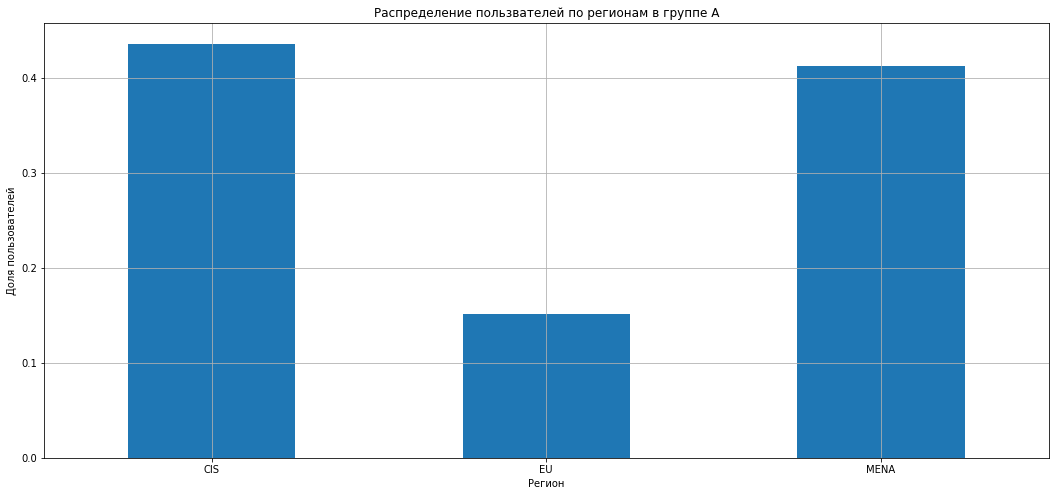

In [30]:
# График 1: Распределение пользвателей по регионам в группе А
plt.figure(figsize=(18, 8))
a_region_share.plot( 
    kind='bar', 
    rot=0, 
    legend=False, 
    title=f'Распределение пользвателей по регионам в группе А'
)
plt.xlabel('Регион')
plt.ylabel('Доля пользователей')
plt.grid()

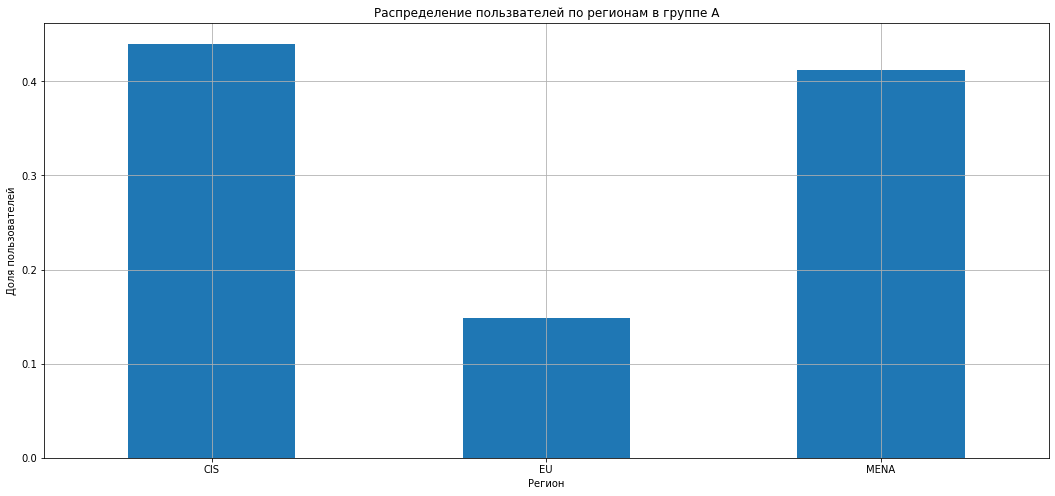

In [31]:
# График 2: Распределение пользвателей по регионам в группе Б
plt.figure(figsize=(18, 8))
b_region_share.plot( 
    kind='bar', 
    rot=0, 
    legend=False, 
    title=f'Распределение пользвателей по регионам в группе А'
)
plt.xlabel('Регион')
plt.ylabel('Доля пользователей')
plt.grid()

#### 3.5. Проверка качества A/B-теста: выводы


Мы обнаружили различие в количестве пользователей в группах А и Б - в группе А на 11 пользователей больше, однако это лишь 0.74 от общего числа пользователей в выборках и значительно не повлияет на тестирование.

Выборки независимы и пользователи в них не пересекаются.

Распределние пользователей по типу устройств почти равномерное, мы можем заметить различия, но они незначительны. Та же ситуация с распределнием пользователей по регионам.

### 4. Проверка результатов A/B-теста

A/B-тест завершён, и у вас есть результаты за все дни проведения эксперимента. Необходимо убедиться в корректности теста и верно интерпретировать результаты.

#### 4.1. Получение результатов теста и подсчёт основной метрики

- Считайте и сохраните в датафрейм `sessions_test` CSV-файл с историческими данными о сессиях пользователей `sessions_project_test.csv`.

- В датафрейме `sessions_test` создайте дополнительный столбец `good_session`. В него войдёт значение `1`, если за одну сессию было просмотрено 4 и более страниц, и значение `0`, если просмотрено меньше.

In [32]:
# Создаем датафрейм с данными за все дни тестирования
sessions_test = pd.read_csv('/datasets/sessions_project_test.csv')
# Добавляем новый столбец с индикацией того, была ли сессия "хорошей"
sessions_test['good_session'] = (sessions_test['page_counter'] >= 4).astype(int)
sessions_test.sort_values('session_date')

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group,good_session
82548,44C81DF8A7D44704,3CAF219CD1DF6196,2025-10-14,2025-10-14 17:15:08,2025-10-14,1,0,2,MENA,Android,A,0
55559,EF740D770C88EDAF,BBA526B6C65C12D3,2025-10-14,2025-10-14 21:35:09,2025-10-14,1,0,3,CIS,Android,A,0
12151,2D3887FC11FDFA5D,43A8D3B3D19FDA62,2025-10-14,2025-10-14 22:02:38,2025-10-14,1,0,1,MENA,Android,A,0
41986,23A49246A627B24D,A21857FC82CAB257,2025-10-14,2025-10-14 00:43:56,2025-10-14,1,0,4,EU,PC,A,1
81319,FDF9FB3CF5ACD148,02E6EE1ACB33DE6F,2025-10-14,2025-10-14 14:27:36,2025-10-15,4,0,7,MENA,Mac,B,1
...,...,...,...,...,...,...,...,...,...,...,...,...
21493,0CAA92FCEE2D434C,3103AFA19A7E3B25,2025-11-02,2025-11-02 17:11:05,2025-10-14,1,0,3,CIS,Android,B,0
89013,59A58046368DFCD5,39A96438D2519BE9,2025-11-02,2025-11-02 05:00:58,2025-10-15,1,0,2,CIS,iPhone,A,0
21488,8D48F8BA5F5EAB0C,6A99E12BFC7098DD,2025-11-02,2025-11-02 13:57:55,2025-10-20,4,0,5,CIS,PC,B,1
9269,0434B5D526FBD1FB,0593275AE50332DC,2025-11-02,2025-11-02 20:45:49,2025-10-20,7,0,3,MENA,PC,B,0


#### 4.2 Формулировка нулевой и альтернативной гипотез. Определение целевой, прокси- и барьерных метрик


Перед тем как проводить А/B-тест, необходимо сформулировать нулевую и альтернативную гипотезы. Напомним изначальное условие: команда разработчиков рекомендательных систем создала новый алгоритм, который, по их мнению, будет показывать более интересный контент для каждого пользователя.

Подумайте, о какой метрике идёт речь и как она будет учтена в формулировке гипотез. Сформулируйте нулевую и альтернативную гипотезы.

Не забывайте, что до проведения эксперимента важно выделять и отслеживать изменение прокси- и барьерных метрик. В имеющихся у вас данных о проведении эксперимента этих метрик нет. Подумайте, какие показатели вы бы выбрали в качестве прокси- и барьерных метрик, если бы проводили этот эксперимент самостоятельно.



Нулевая гипотеза ($H_0$): Новый алгоритм рекомендаций не влияет на вовлеченность пользователей. Доля успешных первых сессий пользователей в тестовой группе равно среднему в контрольной ($\mu_A = \mu_B$).Альтернативная гипотеза ($H_1$): Новый алгоритм рекомендаций повышает вовлеченность. Доля успешных первых сессий пользователейв тестовой группе выше, чем в контрольной ($\mu_A < \mu_B$).


**Основная** - Доля успешных первых сессий пользователей.

**Прокси** - Среднее количество сессий на пользователя. Позволяет быстрее увидеть рост частоты возвратов в приложение.

**Барьерная** - Доля сессий с 1 просмотром. Сигнализирует о росте контента, который отпугивает пользователей.


#### 4.3. Сравнение доли успешных сессий

Перейдем к анализу ключевой метрики — доле успешных первых сессий.

Используйте созданный на первом шаге задания столбец `good_session` и рассчитайте долю успешных первых сессий для выборок A и B, а также разницу в этом показателе. Полученный вывод отобразите на экране.

In [33]:
# Создаем серии с данными групп А и Б по отдельности
a_sessions_test = sessions_test[sessions_test['test_group'] == 'A']
b_sessions_test = sessions_test[sessions_test['test_group'] == 'B']
f_sessions_test_a = a_sessions_test[a_sessions_test['session_number'] == 1]
f_sessions_test_b = b_sessions_test[b_sessions_test['session_number'] == 1]

In [34]:
# Считаем долю успешных сессий в группах А и Б по отдельности
a_good_sessions_share = f_sessions_test_a['good_session'].mean() 
b_good_sessions_share = f_sessions_test_b['good_session'].mean()
   
# Считаем разницу долей успешных сессий в группах А и Б    
diff = (b_good_sessions_share - a_good_sessions_share) * 100

print(f"Доля успешных первых сессий в группе A: {a_good_sessions_share:.2%}")
print(f"Доля успешных первых сессий в группе B: {b_good_sessions_share:.2%}")
print(f"Разница в показателях: {diff:.2f} п.п.")

Доля успешных первых сессий в группе A: 31.57%
Доля успешных первых сессий в группе B: 31.47%
Разница в показателях: -0.11 п.п.


#### 4.4. Насколько статистически значимо изменение ключевой метрики

На предыдущем шаге вы убедились, что количество успешных сессий в тестовой выборке примерно на 1.1% выше, чем в контрольной, но делать выводы только на основе этого значения будет некорректно. Для принятия решения всегда необходимо отвечать на вопрос: является ли это изменение статистически значимым.

- Используя статистический тест, рассчитайте, является ли изменение в метрике доли успешных сессий статистически значимым.

- Выведите на экран полученное значение p-value и свои выводы о статистической значимости. Напомним, что уровень значимости в эксперименте был выбран на уровне 0.05.

In [35]:
from statsmodels.stats.proportion import proportions_ztest

n_a = sessions_test[ 
    (sessions_test.test_group== 'A')&
    (sessions_test.session_number == 1)
].shape[0] # Считаем общее кол-во сессий в группе А

n_b = sessions_test[ 
    (sessions_test.test_group=='B')&
    (sessions_test.session_number == 1)
].shape[0] # Считаем общее кол-во сессий в группе Б

m_a = sessions_test[ # Считаем кол-во успехов в группе A
    (sessions_test.test_group=='A')&(sessions_test.good_session==1)&
    (sessions_test.session_number == 1)
].shape[0] 

m_b = sessions_test[ # Считаем кол-во успехов в группе A
    (sessions_test.test_group=='B')&(sessions_test.good_session==1)&
    (sessions_test.session_number == 1)
].shape[0]

p_a, p_b = m_a/n_a, m_b/n_b # Считаем доли успехов для каждой группы: A и B

if (p_a*n_a > 10)and((1-p_a)*n_a > 10)and(p_b*n_b > 10)and((1-p_b)*n_b > 10): # Проверяем предпосылку о достаточном количестве данных
    print('Предпосылка о достаточном количестве данных выполняется!')
else:
    print('Предпосылка о достаточном количестве данных НЕ выполняется!')

alpha =  0.05 # Устанавливаем уровень значимости


stat_ztest, p_value_ztest = proportions_ztest( # проводим Z-тест пропорций
    [m_a, m_b],
    [n_a, n_b],
    alternative= 'smaller'
)

print(f'pvalue={p_value_ztest}') # Выводим полученное p-value 

if p_value_ztest > alpha:
    print('Нулевая гипотеза находит подтверждение!')
else:
    print('Нулевая гипотеза не находит подтверждения!')



Предпосылка о достаточном количестве данных выполняется!
pvalue=0.5783523649187868
Нулевая гипотеза находит подтверждение!


#### 4.5. Вывод по результатам A/B-эксперимента


В эксперименте участвовали 2 943 пользователя: 1 477 в группе A и 1 466 в группе B. Тестирование длилось 20 дней.

Доля успешных первых сессий составила 31,57% в контрольной группе A и 31,47% в тестовой группе B. Разница составила −0,11 процентного пункта.

Односторонний тест долей дал p-value = 0,578 при уровне значимости 0,05. Статистически значимый рост ключевой метрики не обнаружен. Это не доказывает отсутствие эффекта и не означает эквивалентность вариантов.

Результаты эксперимента не дают основания внедрять новый алгоритм ради подтверждённого улучшения успешности первых сессий. Перед следующим тестом стоит уточнить ожидаемый эффект и требуемую мощность эксперимента.
